In [2]:
import os
import pickle

import colorcet as cc
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import scFates as scf

/data/conda-users/envs/chjini/pysc-2202-gpu/lib/python3.9/site-packages/statsmodels/compat/pandas.py:65: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import Int64Index as NumericIndex


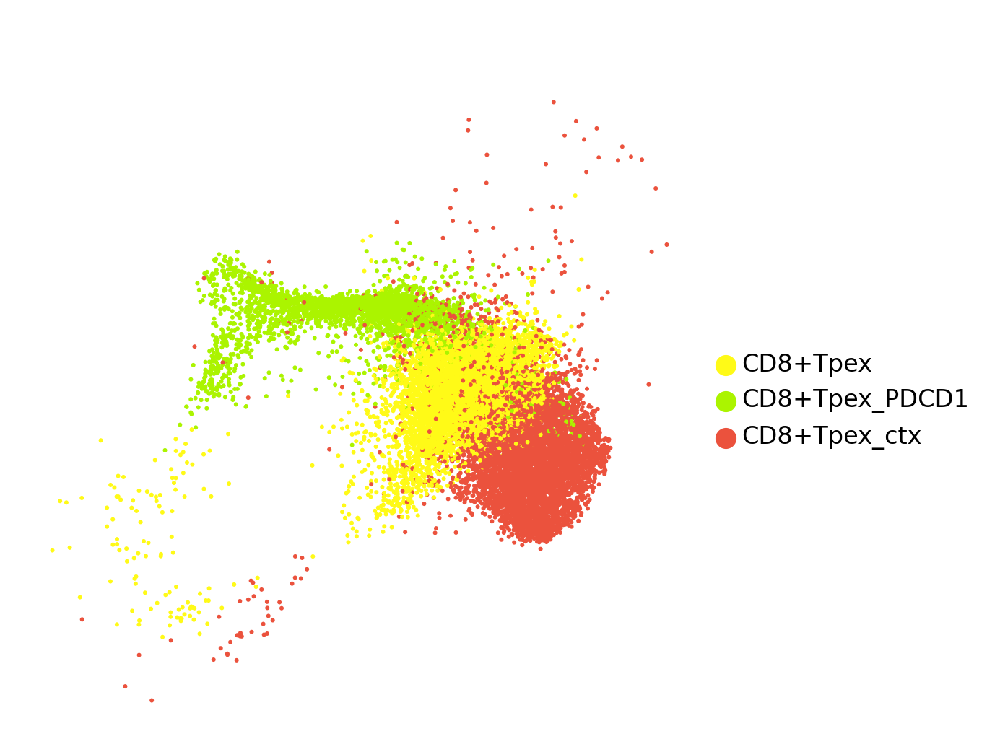

In [ ]:
sc.pl.umap(adata,
           color='annotation_fin2',
           title=" ",
           #title="Major cell lineages",
           #legend_loc='on data',
           #legend_fontsize=4,
           #legend_fontoutline= 1,
           **p_params3,
           #save=f"_lc_total_annotation_fin2"
           )

In [28]:
adata.obs["annotation_fin2"].value_counts()

CD8+Tpex_ctx      5983
CD8+Tpex          5483
CD8+Tpex_PDCD1    3023
Name: annotation_fin2, dtype: int64

In [31]:
adata.obs['annotation_fin2'].cat.reorder_categories(['CD8+Tpex', 'CD8+Tpex_ctx', 'CD8+Tpex_PDCD1'], inplace=True)

/tmp/ipykernel_57713/444225918.py:1: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  adata.obs['annotation_fin2'].cat.reorder_categories(['CD8+Tpex', 'CD8+Tpex_ctx', 'CD8+Tpex_PDCD1'], inplace=True)


## trajectory

In [32]:
sc.pp.neighbors(adata, n_neighbors=30, method="gauss", use_rep="X_scVI", key_added="gauss_neighbors")

computing neighbors
    computing neighbors
    computed neighbors (0:00:25)
    computed connectivities (0:00:03)
    finished: added to `.uns['gauss_neighbors']`
    `.obsp['gauss_neighbors_distances']`, distances for each pair of neighbors
    `.obsp['gauss_neighbors_connectivities']`, weighted adjacency matrix (0:00:29)


In [33]:
sc.tl.diffmap(adata, n_comps=12, neighbors_key="gauss_neighbors")

computing Diffusion Maps using n_comps=12(=n_dcs)
        initialized `.distances` `.connectivities` 
computing transitions
    finished (0:00:00)
    eigenvalues of transition matrix
    [1.0005677  0.975673   0.94721586 0.9092723  0.88443995 0.8804386
     0.8713386  0.8588983  0.853378   0.84207296 0.8283421  0.82405037]
    finished: added
    'X_diffmap', diffmap coordinates (adata.obsm)
    'diffmap_evals', eigenvalues of transition matrix (adata.uns) (0:00:00)


In [34]:
n_dms = 3
adata.obsm["X_diffmap"] = adata.obsm["X_diffmap"][:, 1 : 1 + n_dms]

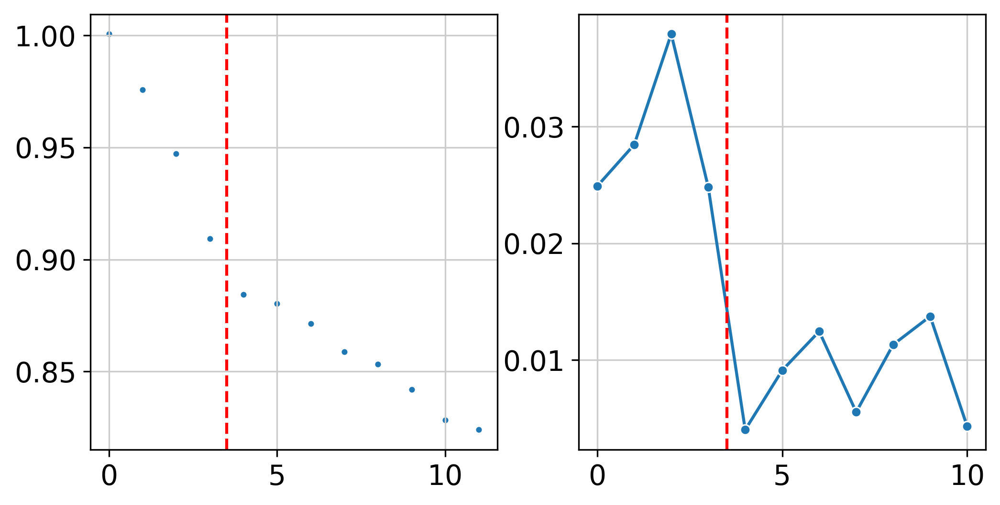

In [35]:
fs = (2*plt.rcParams['figure.figsize'][0], plt.rcParams['figure.figsize'][1])
fig, axes = plt.subplots(1, 2, figsize=fs)
sns.scatterplot(
    x=range(len(adata.uns['diffmap_evals'])),
    y=adata.uns['diffmap_evals'],
    s=10,
    ax=axes[0]
)
sns.lineplot(
    x=range(len(adata.uns['diffmap_evals'])-1),
    y=-np.ediff1d(adata.uns["diffmap_evals"]),
    marker="o",
    ms=5,
    ax=axes[1]
)
for ax in axes:
    ax.axvline(n_dms+0.5, c="r", ls="--")

In [36]:
sc.pp.neighbors(adata, n_neighbors=50, n_pcs=adata.obsm["X_diffmap"].shape[1], use_rep="X_diffmap")

computing neighbors
        initialized `.eigen_values` `.eigen_basis` `.distances_dpt`
    computing neighbors
    computed neighbors (0:00:03)


2025-10-27 17:30:25.537085: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-10-27 17:30:27.966948: I tensorflow/core/util/port.cc:104] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


    computed connectivities (0:01:08)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:11)


In [37]:
sc.tl.umap(adata)

computing UMAP


  0%|          | 0/200 [00:00<?, ?it/s]

    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:14)


In [41]:
adata

AnnData object with n_obs × n_vars = 14489 × 22990
    obs: 'sample_num', 'sample', 'patient_id', 'sample_IOT_DAAN', 'disease', 'gender', 'age', 'batch', 'biopsy_site', 'tissue', 'histology', 'driver_oncogene', 'tumor_pdl1_expression', 'io_preorpost', 'pd_drug', 'stage_initial', 'stage', 'chemo_date', 'biopsy_date', 'ctb_days', 'pfs_days', 'group1', 'group2', 'group3', 'Group1', 'Group2', 'Group3', 'Group4', 'Group5', 'mad4_prd', 'auto_prd', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'complexity', 'S_score', 'G2M_score', 'phase', 'louvain_res1', 'louvain_res2', 'scVI_pred', 'coarse_ann', 'coarse_ann_num', 'louvain_res3', 'annotation', 'umap_density_Group1', 'umap_density_Group2', 'umap_density_Group3', 'umap_density_Group4', 'umap_density_Group5', 'Naiveness_score', 'Residency_score', 'Exhaustion_score', 'Cytotoxicity_score', 'annotation2', 'type', 'file', 'time', 'pat

0.002

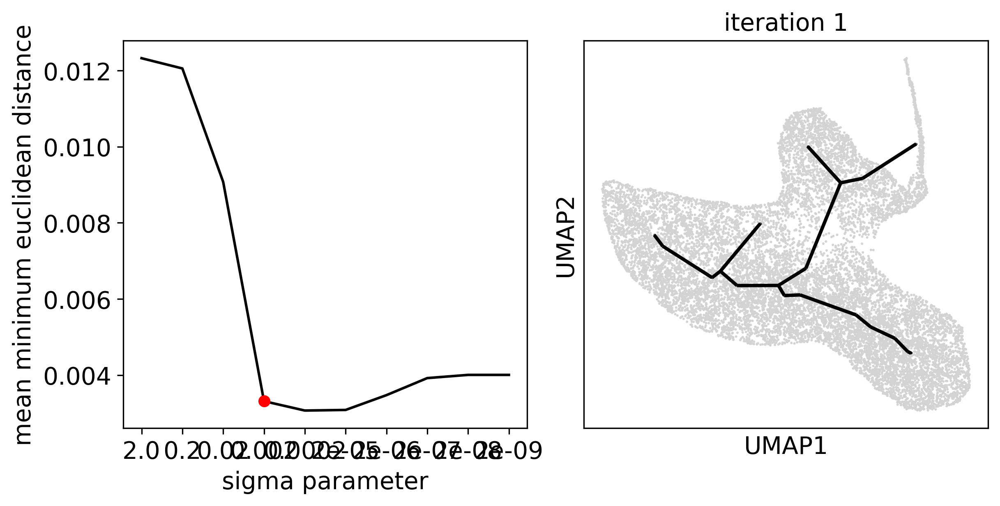

In [43]:
sig = scf.tl.explore_sigma(
    adata,
    Nodes=int(2e1),
    use_rep="X_diffmap",
    #metric="cosine",
    sigmas=[2e1/(10**(i+1)) for i in range(10)],
    device="cpu",
    seed=3, ##0
    plot=True
)
sig

In [44]:
scf.tl.tree(adata, Nodes=int(2e1), use_rep="X_diffmap", method="epg")  #optimization ##여기까지는 scfates 하듯이 하시면 됩니다!

inferring a principal tree --> parameters used 
    20 principal points, mu = 0.1, lambda = 0.01
    finished (0:00:07) --> added 
    .uns['epg'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.


In [45]:
from scipy.sparse import csgraph
from scipy.spatial.distance import cdist
from sklearn.neighbors import KNeighborsTransformer
from umap.umap_ import fuzzy_simplicial_set

In [46]:
B = adata.uns["graph"]["B"].copy()
np.fill_diagonal(B, 0)
B = B + B.transpose()
B = csgraph.shortest_path(B, directed=False)
B = (B <= 10).astype(np.float32)
np.fill_diagonal(B, 10)

R = adata.obsm["X_R"].copy()
R = (R > 0).astype(np.float32)

traj_adj = ((R @ B @ R.transpose()) > 0).astype(np.float32)
np.fill_diagonal(traj_adj, 0.0)

X = adata.obsm["X_diffmap"].copy()

In [47]:
knt = KNeighborsTransformer(metric="euclidean", n_jobs=sc.settings.n_jobs)
knt.fit(X)

KNeighborsTransformer(metric='euclidean', n_jobs=8)

In [48]:
n_neighbors = 20
knn_ind = {}
knn_dist = {}
for c in range(traj_adj.shape[0]):
    traj_adj_idx = np.argwhere(traj_adj[c]).ravel()
    c_rep = np.expand_dims(adata.obsm["X_diffmap"][c], 0)
    traj_adj_dist = pd.Series(
        cdist(c_rep, adata.obsm["X_diffmap"][traj_adj_idx]).ravel(),
        index=traj_adj_idx,
    ).sort_values()
    if len(traj_adj_dist) >= n_neighbors:
        knn_ind[c] = list(traj_adj_dist.index[:n_neighbors])
        knn_dist[c] = traj_adj_dist.to_list()[:n_neighbors]
    else:
        _dist, _ind = knt.kneighbors(
            c_rep, n_neighbors=n_neighbors + len(traj_adj_dist)
        )
        _ind = _ind.ravel()
        _dist = _dist.ravel()
        _traj_adj_idx = set(traj_adj_idx) | {c}
        idx_mask = [x not in _traj_adj_idx for x in _ind]
        _knn_dist = pd.Series(_dist[idx_mask], index=_ind[idx_mask]).sort_values()
        _n_from_knn = n_neighbors - len(traj_adj_dist)
        knn_ind[c] = list(traj_adj_dist.index) + list(_knn_dist.index[:_n_from_knn])
        knn_dist[c] = (
            traj_adj_dist.to_list()[:n_neighbors]
            + _knn_dist.to_list()[:_n_from_knn]
        )

conn, _, _, dist = fuzzy_simplicial_set(
    np.zeros((adata.shape[0], 1), dtype=np.float32),
    n_neighbors=n_neighbors,
    random_state=None,
    metric=None,
    knn_indices=pd.DataFrame(knn_ind).transpose().astype(np.int32).to_numpy(),
    knn_dists=pd.DataFrame(knn_dist).transpose().astype(np.float32).to_numpy(),
    return_dists=True,
)

adata.uns["trajectory"] = dict(
    connectivities_key="traj_conn",
    distances_key="traj_dist",
    params=dict(
        n_neighbors=n_neighbors,
        method="umap",
        random_state=0,
        metric="euclidean",
        use_rep="X_diffmap",
        n_pcs=adata.obsm["X_diffmap"].shape[1],
    ),
)

adata.obsp["traj_conn"] = conn
adata.obsp["traj_dist"] = dist.tocsr()

In [49]:
sc.tl.umap(adata, min_dist=0.4, spread=0.5, maxiter=int(1e3), neighbors_key="trajectory")

computing UMAP


  0%|          | 0/1000 [00:00<?, ?it/s]

    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:56)


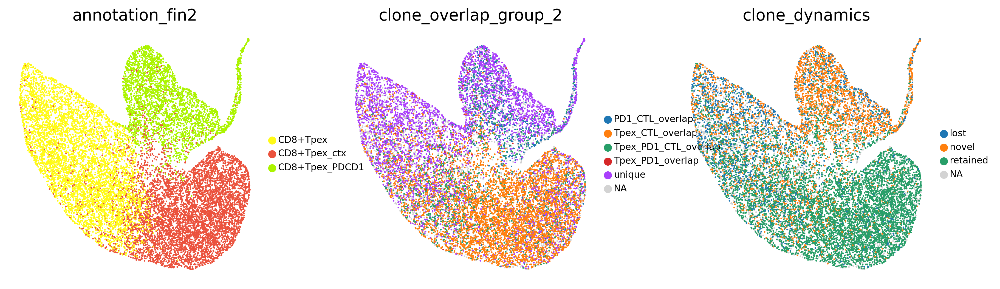

In [50]:
sc.pl.umap(
    adata,
    color=["annotation_fin2", "clone_overlap_group_2", "clone_dynamics"],
    **p_params2
)

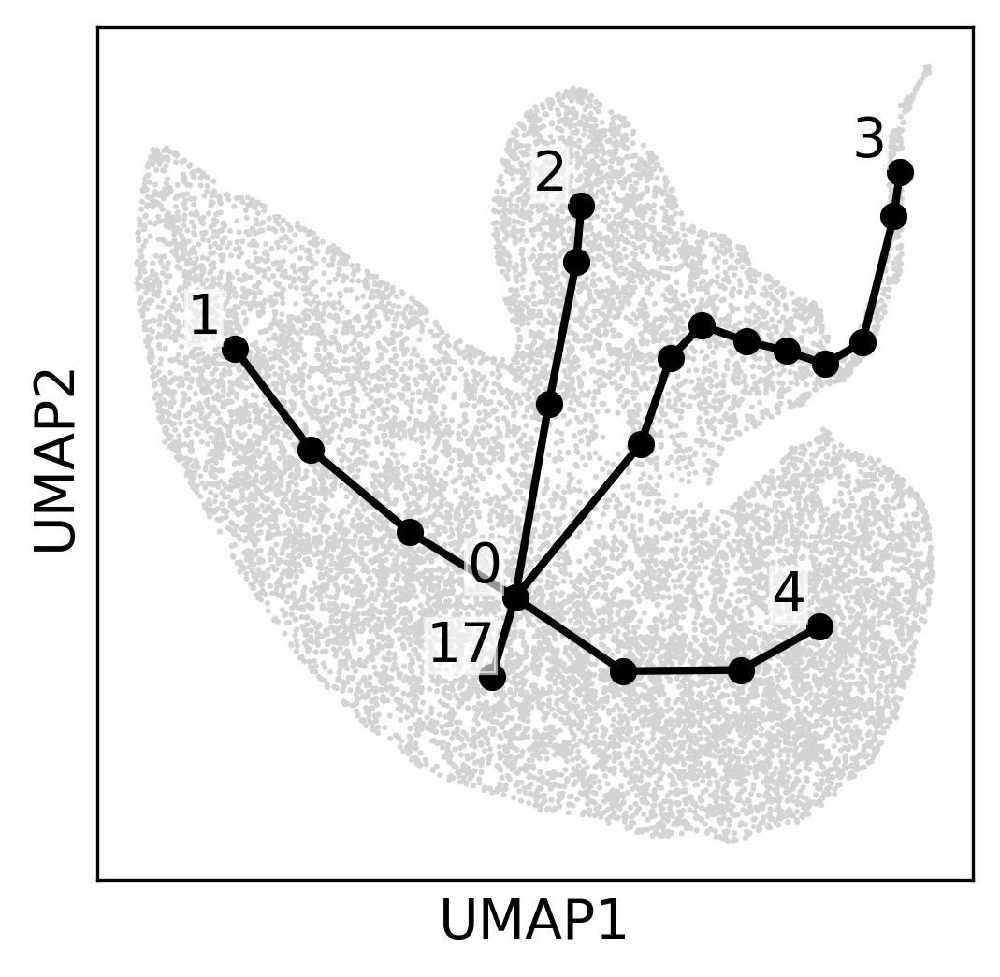

In [51]:
scf.pl.graph(adata)

In [52]:
adata

AnnData object with n_obs × n_vars = 14489 × 22990
    obs: 'sample_num', 'sample', 'patient_id', 'sample_IOT_DAAN', 'disease', 'gender', 'age', 'batch', 'biopsy_site', 'tissue', 'histology', 'driver_oncogene', 'tumor_pdl1_expression', 'io_preorpost', 'pd_drug', 'stage_initial', 'stage', 'chemo_date', 'biopsy_date', 'ctb_days', 'pfs_days', 'group1', 'group2', 'group3', 'Group1', 'Group2', 'Group3', 'Group4', 'Group5', 'mad4_prd', 'auto_prd', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'complexity', 'S_score', 'G2M_score', 'phase', 'louvain_res1', 'louvain_res2', 'scVI_pred', 'coarse_ann', 'coarse_ann_num', 'louvain_res3', 'annotation', 'umap_density_Group1', 'umap_density_Group2', 'umap_density_Group3', 'umap_density_Group4', 'umap_density_Group5', 'Naiveness_score', 'Residency_score', 'Exhaustion_score', 'Cytotoxicity_score', 'annotation2', 'type', 'file', 'time', 'pat

In [53]:
scf.tl.root(adata, 1)

node 1 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [54]:
scf.tl.pseudotime(
        adata,
        n_jobs=-1,
        n_map=15,
        seed=3
    )

projecting cells onto the principal graph
    mappings:   0%|          | 0/15 [00:00<?, ?it/s]

/data/conda-users/envs/chjini/pysc-2202-gpu/lib/python3.9/site-packages/statsmodels/compat/pandas.py:65: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import Int64Index as NumericIndex
/data/conda-users/envs/chjini/pysc-2202-gpu/lib/python3.9/site-packages/statsmodels/compat/pandas.py:65: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import Int64Index as NumericIndex
/data/conda-users/envs/chjini/pysc-2202-gpu/lib/python3.9/site-packages/statsmodels/compat/pandas.py:65: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import Int64Index as NumericIndex
/data/conda-users/envs/chjini/pysc-2202-gpu/lib/python3.9/site-packages/statsmodel

    mappings: 100%|██████████| 15/15 [00:44<00:00,  2.98s/it]
    finished (0:00:51) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


In [55]:
sc.settings.set_figure_params(
    dpi=150,
    dpi_save=600,
    vector_friendly=True,
    #fontsize=10,
    format="png",
    facecolor="white",
    transparent=True
)

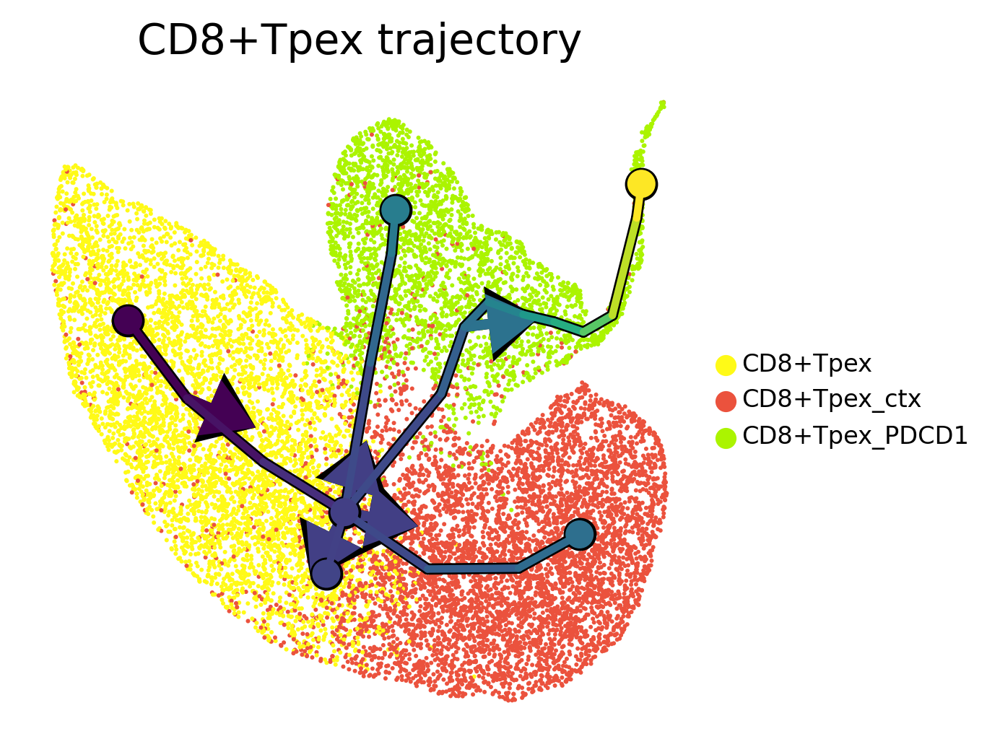

In [11]:
scf.pl.trajectory(adata, 
                  basis="umap", 
                  color_cells="annotation_fin2", 
                  arrows=True, 
                  arrow_offset=2, 
                  scale_path=0.5, 
                  frameon=False,
                  arrows_kwds = {'headwidth':0.005, 'width': 0.003, 'scale': 0.1},
                  #arrows=True,
                  #arrow_offset=60,
                  title="CD8+Tpex trajectory",
                  legend_fontsize='xx-small', 
                  #s=1,
                  #show=False,
                  save=f"_cdtex_pseudotime_ann.pdf",
                  )

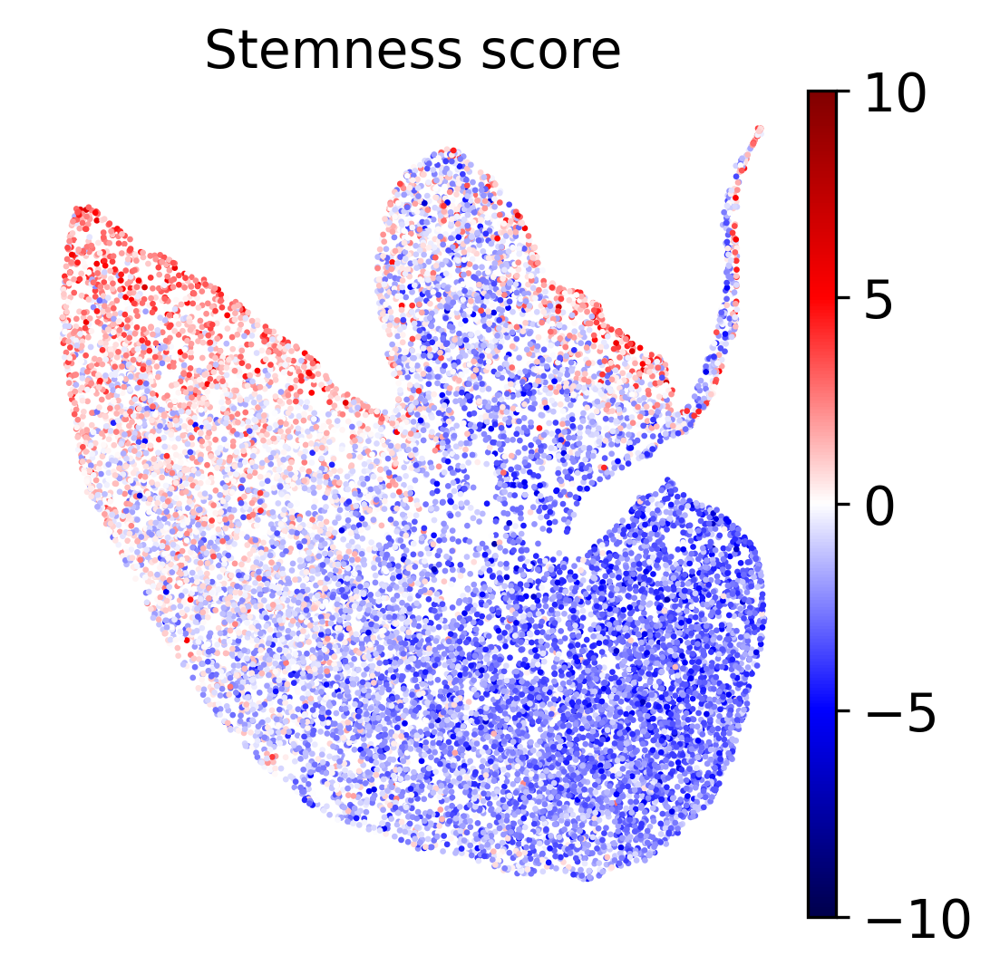

In [75]:
sc.pl.umap(adata, color=['stemness_score'],          
           title="Stemness score",
           frameon=False,
           sort_order=False,
           #ax=ax,
           cmap='seismic',
           vmin=-10,
           vmax=10,
           vcenter=0,
           size=15e4/adata.shape[0],
           save=f"_lc_TNK_cd8tex_stem_score.pdf"
          )

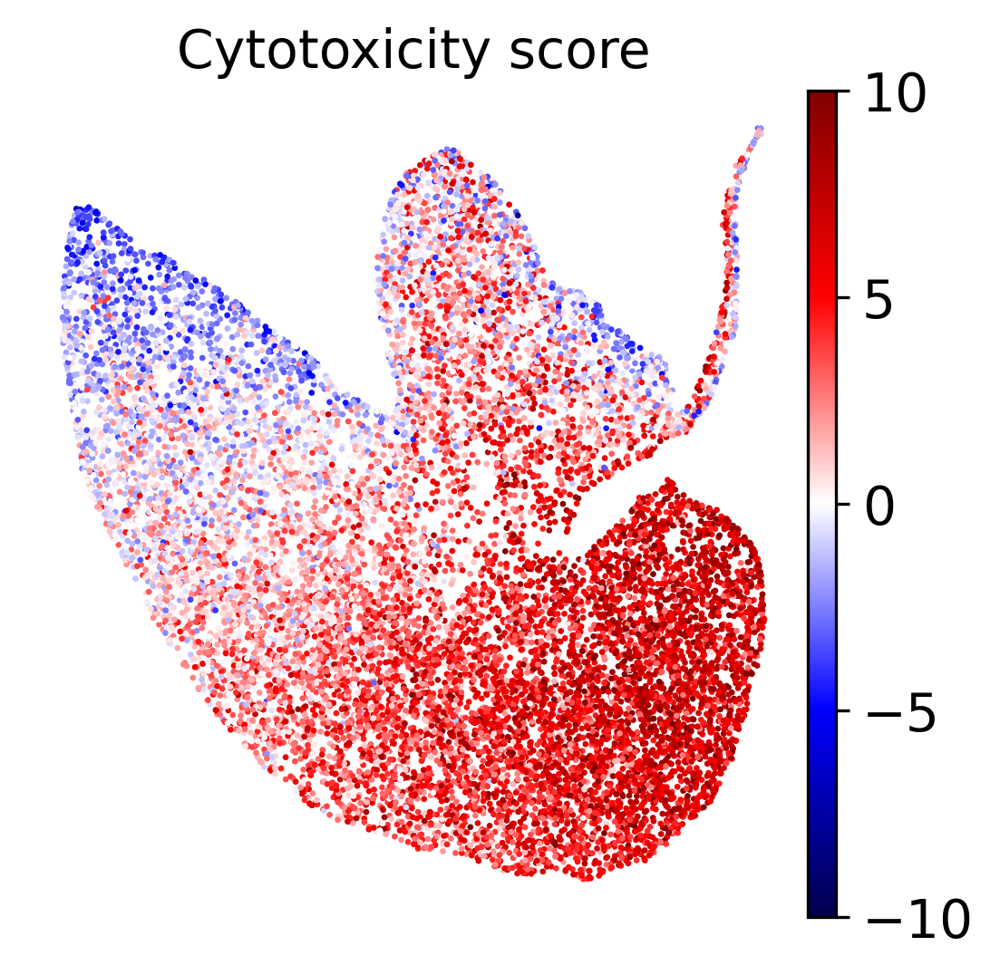

In [80]:
sc.pl.umap(adata, color=['cytotoxicity_score'],          
           title="Cytotoxicity score",
           frameon=False,
           sort_order=False,
           #ax=ax,
           cmap='seismic',
           vmin=-10,
           vmax=10,
           vcenter=0,
           size=15e4/adata.shape[0],
           save=f"_lc_TNK_cd8tex_cyto_score.pdf"
          )

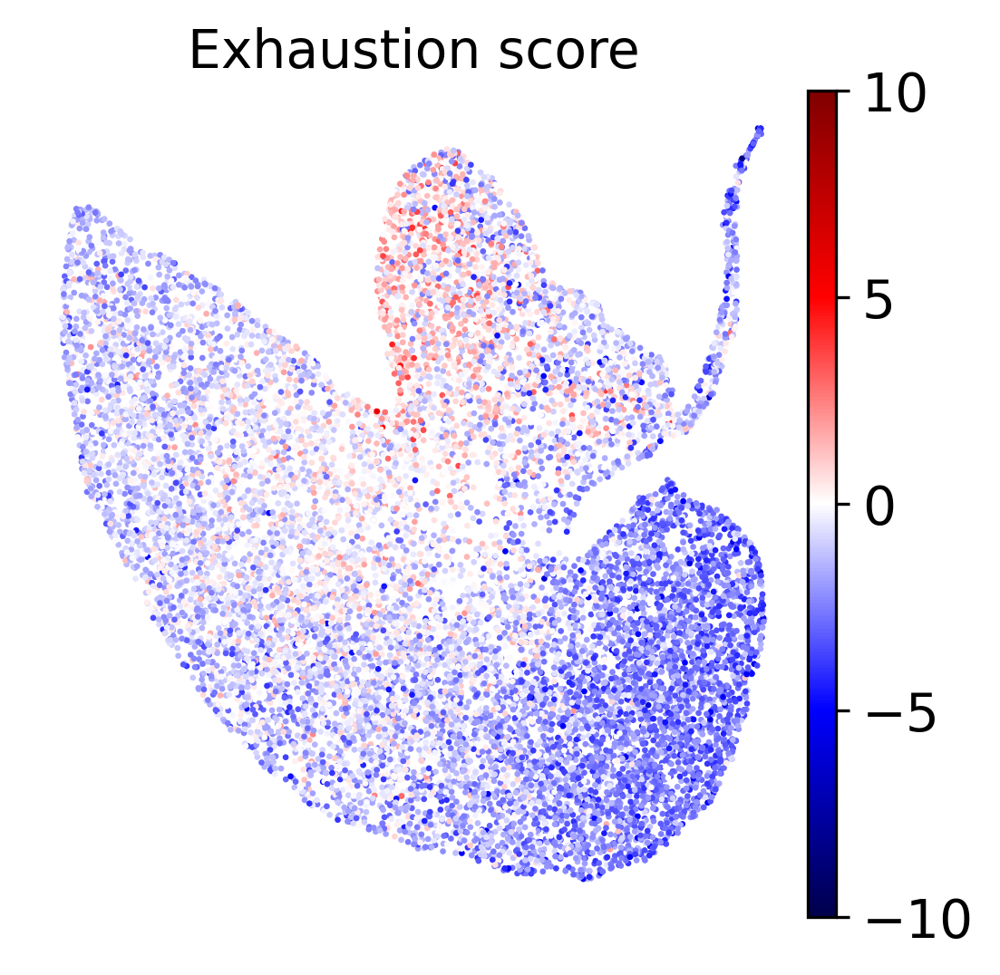

In [82]:
sc.pl.umap(adata, color=['exhaustion_score'],          
           title="Exhaustion score",
           frameon=False,
           sort_order=False,
           #ax=ax,
           cmap='seismic',
           vmin=-10,
           vmax=10,
           vcenter=0,
           size=15e4/adata.shape[0],
           save=f"_lc_TNK_cd8tex_exh_score"
          )

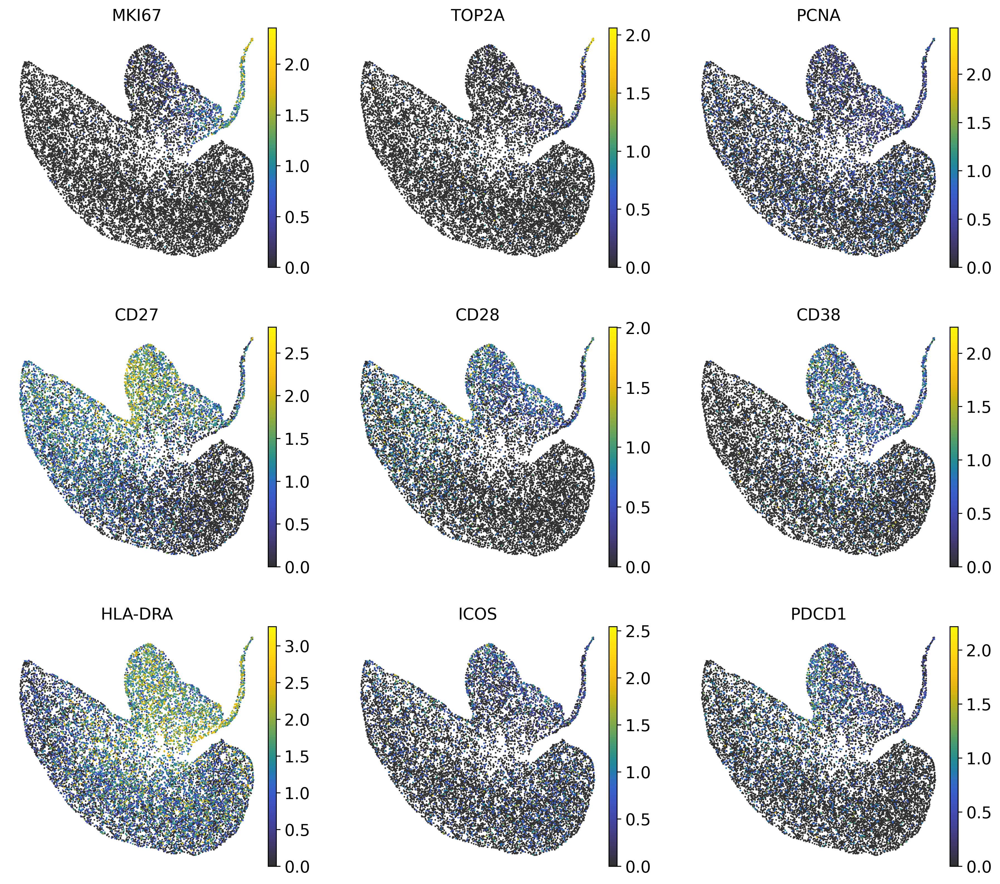

In [78]:
sc.pl.umap(adata, color=['MKI67', 'TOP2A', 'PCNA', 'CD27', 'CD28', 'CD38', 'HLA-DRA', 'ICOS', 'PDCD1'], ncols=3, **p_params)

## umap